In [25]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import seaborn as sns
import matplotlib.pyplot as plt 
from sklearn.tree import plot_tree
import numpy as np

In [2]:
housing_data=pd.read_excel("realistic_housing_data.xlsx")

In [3]:
print(housing_data.head())
print(housing_data.shape)

   bedrooms  bathrooms  sqft  lot_size  age  year_built  garage  location  \
0         3          5  2229     12569   38        1986       1     Rural   
1         3          2  1897      8942   27        1997       3     Rural   
2         4          2  2397      4826   46        1978       0  Downtown   
3         5          3  2849      2490   39        1985       2     Hills   
4         2          3  1895     11910   41        1983       1  Downtown   

  house_type  condition  has_pool  has_fireplace  has_basement  school_rating  \
0      Condo          4         0              1             0             10   
1  Townhouse          3         0              0             1              3   
2  Townhouse          2         0              0             0              6   
3      House          3         0              1             1              4   
4  Townhouse          4         0              0             0              5   

    price  
0  199148  
1  152932  
2  230854  
3 

In [4]:
housing_data.columns

Index(['bedrooms', 'bathrooms', 'sqft', 'lot_size', 'age', 'year_built',
       'garage', 'location', 'house_type', 'condition', 'has_pool',
       'has_fireplace', 'has_basement', 'school_rating', 'price'],
      dtype='str')

In [5]:
housing_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   bedrooms       5000 non-null   int64
 1   bathrooms      5000 non-null   int64
 2   sqft           5000 non-null   int64
 3   lot_size       5000 non-null   int64
 4   age            5000 non-null   int64
 5   year_built     5000 non-null   int64
 6   garage         5000 non-null   int64
 7   location       5000 non-null   str  
 8   house_type     5000 non-null   str  
 9   condition      5000 non-null   int64
 10  has_pool       5000 non-null   int64
 11  has_fireplace  5000 non-null   int64
 12  has_basement   5000 non-null   int64
 13  school_rating  5000 non-null   int64
 14  price          5000 non-null   int64
dtypes: int64(13), str(2)
memory usage: 586.1 KB


In [6]:
housing_data.describe()

,bedrooms,bathrooms,sqft,lot_size,age,year_built,garage,condition,has_pool,has_fireplace,has_basement,school_rating,price
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5.000000e+03
mean,3.20160,2.410600,2160.496600,8090.264200,24.581000,1999.419000,1.384600,3.259600,0.197000,0.404400,0.609600,5.71220,3.381644e+05
std,1.28019,1.066881,436.624535,3021.882128,14.316132,14.316132,0.904238,0.975089,0.397772,0.490825,0.487889,2.36831,1.520593e+05
min,1.00000,1.000000,858.000000,1000.000000,0.000000,1975.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.00000,6.435600e+04
25%,2.00000,2.000000,1851.000000,5918.250000,12.000000,1987.000000,1.000000,3.000000,0.000000,0.000000,0.000000,4.00000,2.276008e+05
50%,3.00000,2.000000,2153.000000,8124.000000,25.000000,1999.000000,1.000000,3.000000,0.000000,0.000000,1.000000,6.00000,3.098330e+05
75%,4.00000,3.000000,2455.250000,10211.000000,37.000000,2012.000000,2.000000,4.000000,0.000000,1.000000,1.000000,7.00000,4.198550e+05
max,6.00000,5.000000,3620.000000,19332.000000,49.000000,2024.000000,3.000000,5.000000,1.000000,1.000000,1.000000,10.00000,1.282622e+06


In [7]:
housing_data.isna().sum()

bedrooms         0
bathrooms        0
sqft             0
lot_size         0
age              0
year_built       0
garage           0
location         0
house_type       0
condition        0
has_pool         0
has_fireplace    0
has_basement     0
school_rating    0
price            0
dtype: int64

## correlation heatmap

<Axes: >

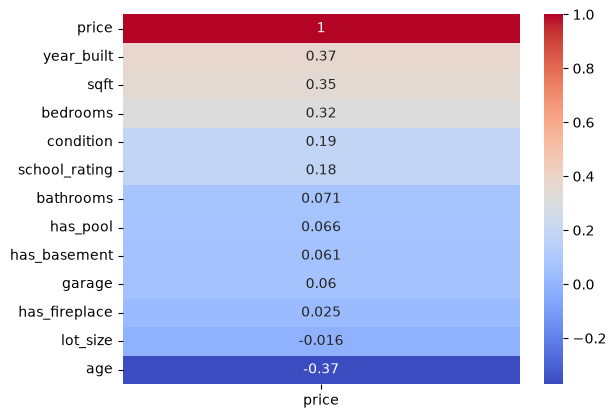

In [8]:

housing_corr = housing_data.corr(numeric_only=True)[['price']].sort_values(by='price', ascending=False)
sns.heatmap(housing_corr, annot=True, cmap='coolwarm')

## select the feature

In [9]:
x=housing_data.drop(columns=['price'])
y=housing_data['price']

## split the data

In [10]:
catogorical = x.select_dtypes(include='O').columns
numerical=x.select_dtypes(include=['number']).columns

C:\Users\ROBIN\AppData\Local\Temp\ipykernel_12188\2720712535.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  catogorical = x.select_dtypes(include='O').columns


In [11]:
catogorical

Index(['location', 'house_type'], dtype='str')

In [12]:
numerical

Index(['bedrooms', 'bathrooms', 'sqft', 'lot_size', 'age', 'year_built',
       'garage', 'condition', 'has_pool', 'has_fireplace', 'has_basement',
       'school_rating'],
      dtype='str')

## preprocessing

In [13]:
preprocessor=ColumnTransformer(transformers=[('cat',OneHotEncoder(handle_unknown='ignore'),catogorical),('num',StandardScaler(),numerical)])

## build the pipeline and Randomforest

In [17]:
pipeline=Pipeline([('preprocessing',preprocessor),('model',RandomForestRegressor(n_estimators=100,random_state=42))])

## Train the model

In [18]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=42,test_size=0.2)

In [19]:
pipeline.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['bedrooms','bathrooms','sqft',...,'has_fireplace','has_basement', 'school_rating']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subs

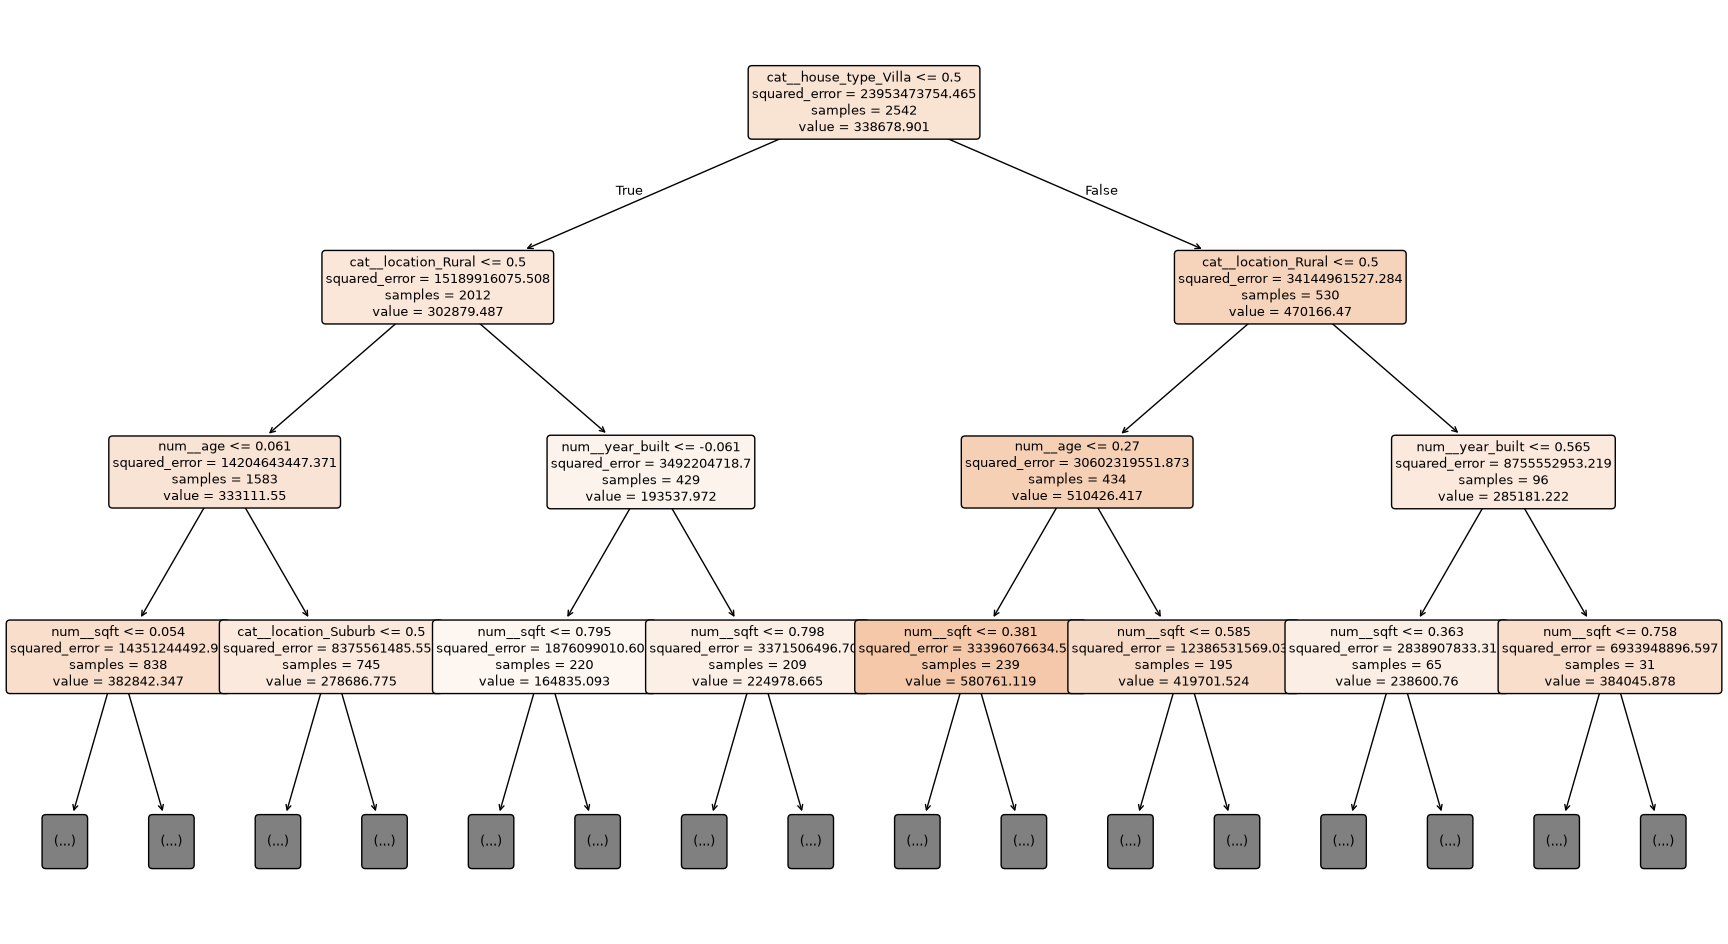

In [21]:
feature_names = pipeline.named_steps['preprocessing'].get_feature_names_out()

single_tree = pipeline.named_steps['model'].estimators_[0]

plt.figure(figsize=(22, 12))
plot_tree(
    single_tree, 
    feature_names=feature_names, 
    max_depth=3,            # Clarity-kaga top levels matum paaka (depth adhigama podalam)
    filled=True, 
    rounded=True,
    fontsize=9
)
plt.show()

## predict the model

In [22]:
y_pred=pipeline.predict(x_test)

## evaluate the model

In [23]:
mean_absolute_error(y_test,y_pred)

38710.337100000004

In [32]:
mse=mean_squared_error(y_test,y_pred)
mse

2775797940.0097466

In [34]:
rmse=np.sqrt(mse)
print(rmse)

52685.841931298266


## Actual data vs predicted data

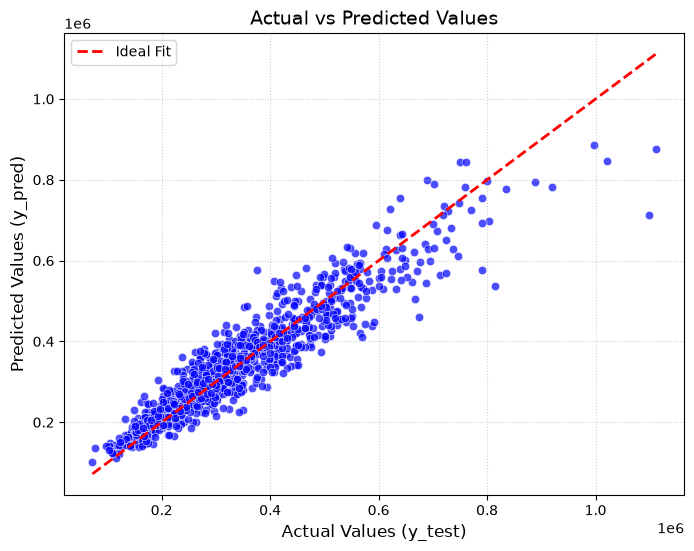

In [35]:


plt.figure(figsize=(8, 6))

# Actual vs Predicted scatter plot
sns.scatterplot(x=y_test, y=y_pred, alpha=0.7, color='blue')

# Perfect prediction line (Diagonal line)
p1 = min(min(y_test), min(y_pred))
p2 = max(max(y_test), max(y_pred))
plt.plot([p1, p2], [p1, p2], color='red', linestyle='--', lw=2, label='Ideal Fit')

plt.xlabel("Actual Values (y_test)", fontsize=12)
plt.ylabel("Predicted Values (y_pred)", fontsize=12)
plt.title("Actual vs Predicted Values", fontsize=14)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

## Feature Importance Plot

C:\Users\ROBIN\AppData\Local\Temp\ipykernel_12188\1919785928.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_imp, palette='viridis')


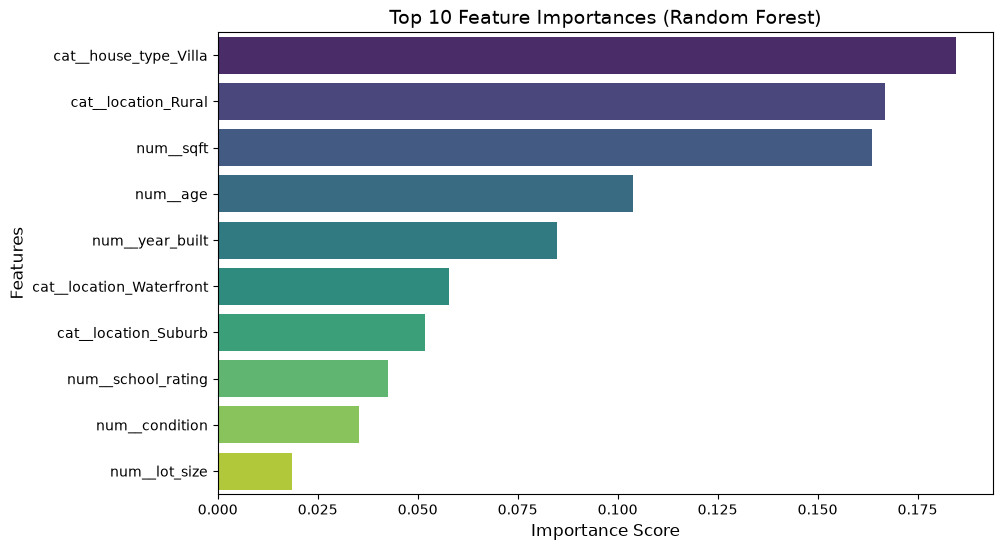

In [36]:
feature_names = pipeline.named_steps['preprocessing'].get_feature_names_out()
importances = pipeline.named_steps['model'].feature_importances_


feat_imp = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_imp = feat_imp.sort_values(by='Importance', ascending=False).head(10) # Top 10 features

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp, palette='viridis')
plt.title("Top 10 Feature Importances (Random Forest)", fontsize=14)
plt.xlabel("Importance Score", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.show()